# Does fitting RNA and protein together clarify shared processes?

The independent fits gave Asteron two descriptions of the same inhabitants. We now ask whether one coordinate system can describe both measurements. **We fit one six-factor Gaussian MOFA-FLEX model to Asteron's RNA and protein together**: 80 shared inhabitants, 90 RNA features and 60 different protein features.

We will align the observations, fit shared sample scores with view-specific weights, and compare this result with the exact independent fits from notebook 04. Borealis remains outside this analysis.

**Predict:** should sharing information help the inflammatory process? Must it also help a noisy process that only protein measures?

### Load the same saved experiment

The local `course_utils` import supplies the data readers, alignment and plotting helpers, comparison functions and `FIT` settings. `load_experiment()` reads the four canonical AnnData tables without regenerating them or exposing the teacher activities. We select Asteron's two views below; loading Borealis does not make it part of the fit.

In [2]:
from pathlib import Path
import sys, time
HERE = Path.cwd() if Path('course_utils.py').exists() else Path.cwd() / 'notebooks'
sys.path.insert(0, str(HERE))
from course_utils import *
from IPython.display import display
from sklearn.decomposition import PCA
# Observations only. Ground truth is loaded explicitly for later diagnostics.
data = load_experiment()

### Check the settings before the joint fit

We import MOFA-FLEX and keep one PyTorch CPU thread. Printing `FIT` shows the Gaussian likelihood, seed, .02 base learning rate and stopping controls used by the **upcoming Asteron two-view model**. These settings are passed with `**FIT`; the constructor below separately chooses factor count, priors and initialisation.

In [3]:
import mofaflex as mf
import torch
torch.set_num_threads(1)
print('MOFA-FLEX', mf.__version__)
print('Training settings:', FIT)

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.

MOFA-FLEX 0.2.0rc2.dev16+g2710274b7
Training settings: {'device': 'cpu', 'likelihoods': 'Normal', 'seed': 42, 'save_path': False, 'max_epochs': 1200, 'lr': 0.02, 'early_stopper_patience': 250, 'batch_size': 0, 'subset_var': None, 'plot_data_overview': False, 'update_every': -1, 'scale_elbo': True}


/Users/flores/Dropbox/EBI/Teaching/VIB/MOFA_training/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
/Users/flores/Dropbox/EBI/Teaching/VIB/MOFA_training/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.


## Make sure the two views describe the same inhabitants

Before fitting **the Asteron two-view model**, we select copies of its RNA and protein tables. The code deliberately reverses protein row order, then repairs it using RNA sample identifiers. Equal row counts alone would not guarantee correct pairing.

`make_mudata(views)` checks that the views contain the same sample identifiers, copies their rows into the order of the first view, constructs the multiview MuData container and attaches sample metadata. It does not concatenate RNA genes with protein features, scale abundances or infer factors. We retain two distinct feature spaces linked by the same 80 inhabitants.

Read the assertions as scientific checks on who is paired with whom. What would the joint model be assuming if we silently paired the reversed protein rows by position?

In [4]:
views = {v: a.copy() for v, a in data['Asteron'].items()}
views['Protein'] = views['Protein'][::-1].copy()
ids = views['RNA'].obs_names
assert set(ids) == set(views['Protein'].obs_names)
views['Protein'] = views['Protein'][ids].copy()
assert views['RNA'].obs_names.equals(views['Protein'].obs_names)
mdata = make_mudata(views)
display(mdata)

MuData object with n_obs × n_vars = 80 × 150
  obs:	'planet', 'disease', 'batch'
  2 modalities
    RNA:	80 × 90
      obs:	'planet', 'disease', 'batch'
      layers:	None
    Protein:	80 × 60
      obs:	'planet', 'disease', 'batch'
      layers:	None

## Fit one sample representation for both Asteron views

We now fit **six Gaussian factors jointly to Asteron RNA and protein**, with Normal factor priors, SpikeSlab weights and PCA initialisation:

$$\widetilde Y^{(m,A)}_{80\times D_m}\approx Z^{(A)}_{80\times6}W^{(m)}_{6\times D_m}.$$

The 80 × 6 score matrix Z is shared between views. The two weight matrices are different: 6 × 90 for RNA and 6 × 60 for protein in the equation. A factor can contribute strongly to one view and weakly to the other. The model does not require identical genes and proteins or separate sample scores for each view.

`joint.fit(mdata, **FIT)` performs inference using the printed settings: seed 42, base learning rate .02 and the common training controls. Gaussian preprocessing centres features and scales each view by one scalar. `scale_elbo=True` separately balances likelihood contributions for views of different widths; it does not make their information content identical.

`get_factors()` returns one sample-group table, so selecting its first dictionary value gives all 80 × 6 shared scores. `.loc[ids]` restores inhabitant order. `export_fit(joint, 'joint')` writes scores, view-specific weights, total R² and loss under `results/joint/`; it does not fit a second model.

**Predict:** could these shared coordinates also describe technical variation?

In [5]:
joint = mf.terms.MofaFlex(n_factors=6, factor_prior='Normal',
                          weight_prior='SpikeSlab', init_factors='pca')
joint.fit(mdata, **FIT)
z_joint = next(iter(joint.get_factors().values())).loc[ids]
export_fit(joint, 'joint')

INFO	Initializing factors using 'pca' method...


INFO 	 Guessed max_plate_nesting = 2


INFO	Training converged after 1093 epochs.


### Follow one set of factors into two feature spaces

These plots describe the **one fitted Asteron multiview model**. `score_plot` displays its first two score columns and adds disease colours after training. `get_weights()` returns one feature × six table per view; `weights_plot` selects the 18 strongest features in each supplied table and shows their signed weights. Factor columns now belong to the same model across the two weight panels, although selected feature rows differ.

`r2_plot(joint)` displays factor-alone reconstruction R² by view and returns whole-model R² for the printed table. Factor-alone values need not add to the total. `diagnostics(joint)` plots stochastic negative-ELBO loss and summarises its late values. These are reconstruction and fitting diagnostics, not measures of truth recovery.

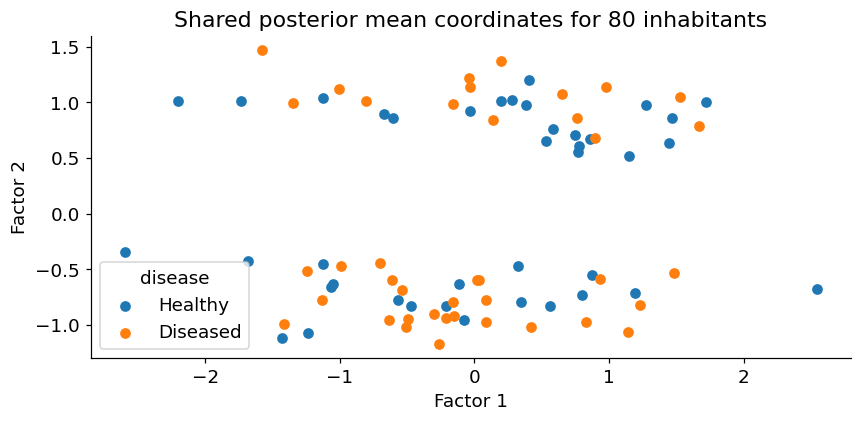

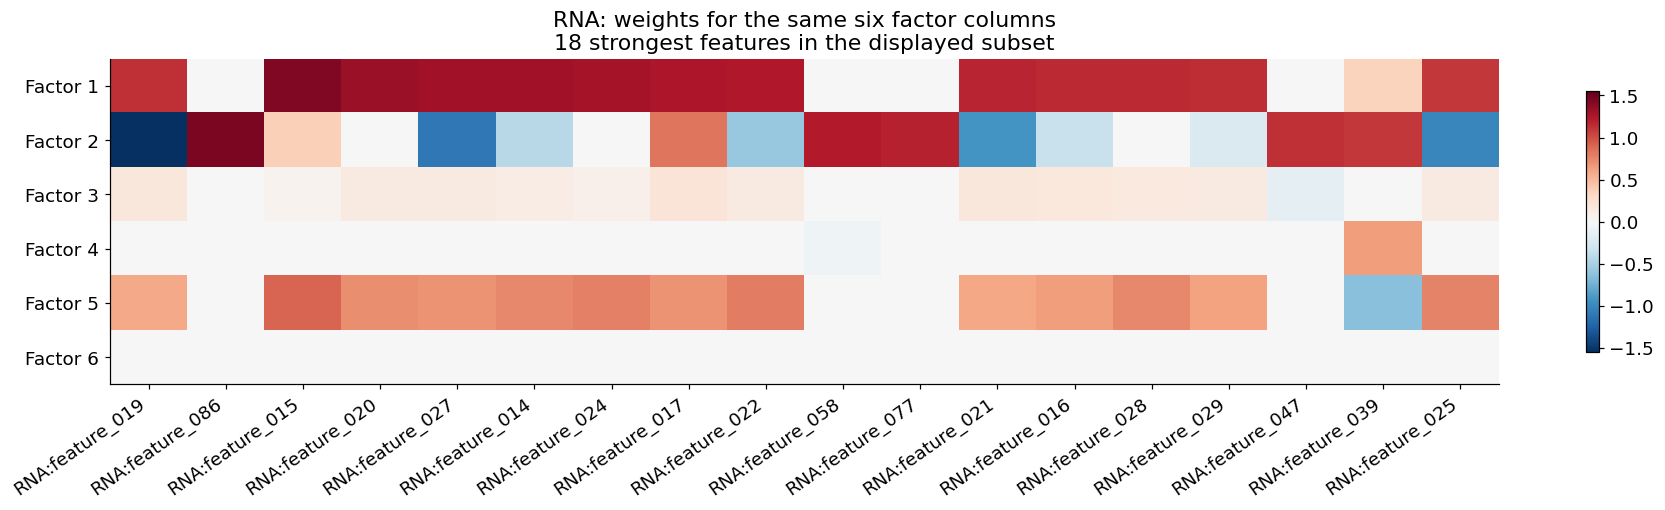

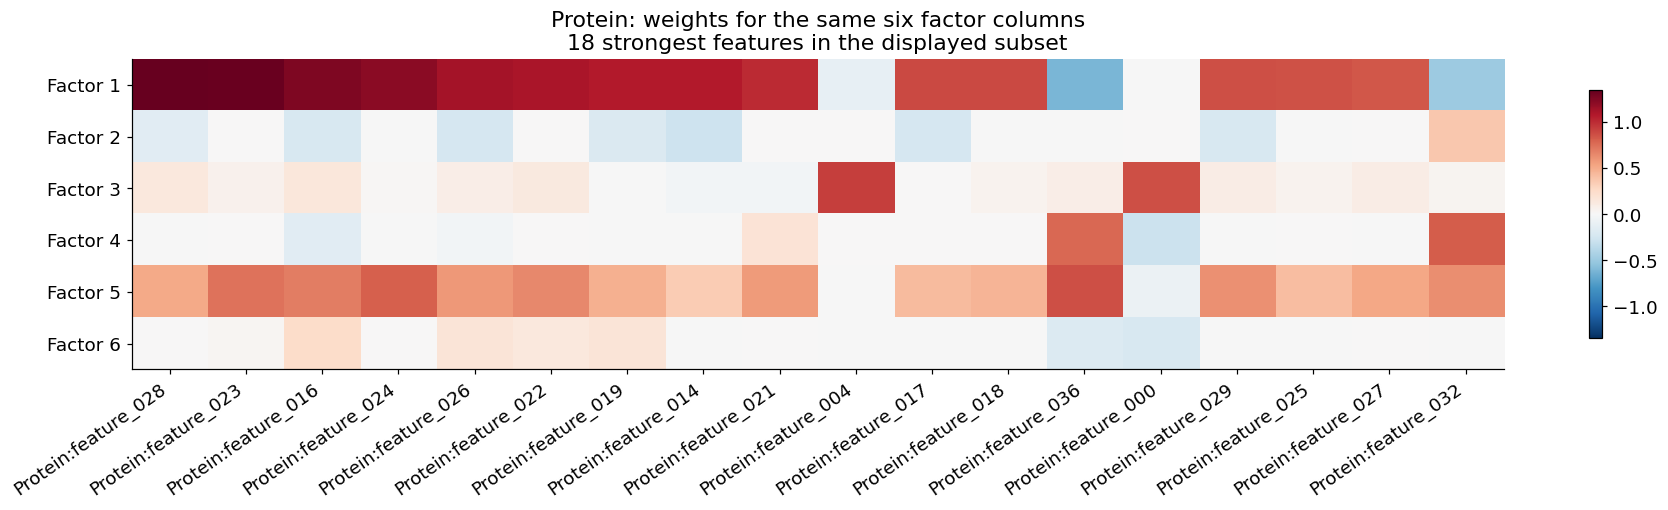

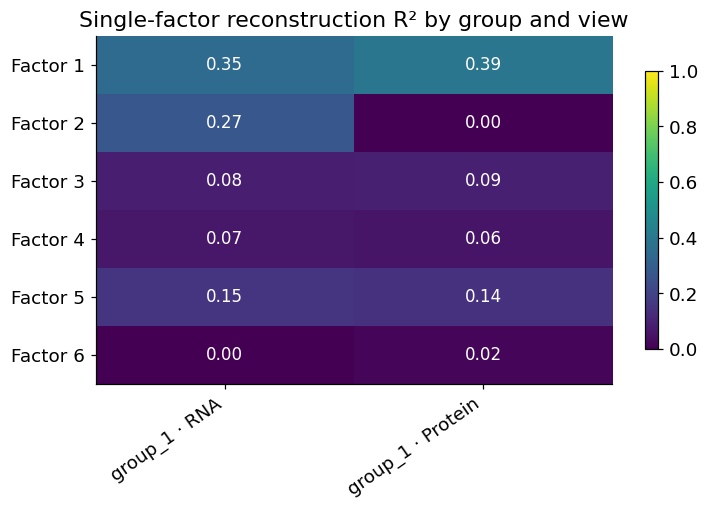

,group,view,R2
0,group_1,RNA,0.873043
1,group_1,Protein,0.671326


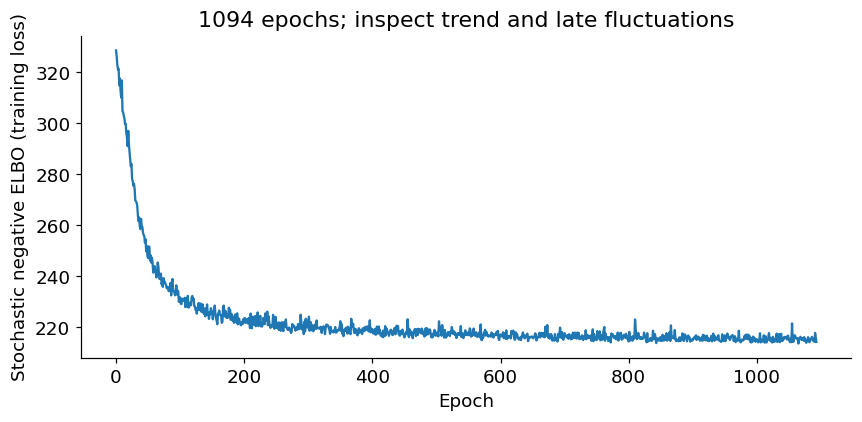

Finite loss: True | last-100 mean: 215.381


In [6]:
score_plot(z_joint, mdata.obs, color='disease', title='Shared posterior mean coordinates for 80 inhabitants')
for v, w in joint.get_weights().items():
    weights_plot(w, f'{v}: weights for the same six factor columns')
display(r2_plot(joint))
diagnostics(joint)

## Compare the joint representation with the actual separate fits

We now compare the **joint Asteron two-view fit** with **Asteron RNA-only and protein-only fits from notebook 04**. `read_scores(name)` reads the saved score CSVs from the named `results/` folder; it neither retrains those models nor loads a serialized fitted object. `.loc[ids]` aligns all three representations to the same inhabitants.

`load_truth()` reveals the teacher activities only for evaluation. We ask two different questions. `crosscorr(z, true_scores).abs().max()` finds, for each true process, its strongest correlation with a single learned axis. `truth_projection(z, true_scores)` centres matched rows and fits a least-squares combination of all learned scores to each activity, reporting training activity-recovery R². The diagnostic regression does not change the omics model. A process can be spread across several learned axes, making these two summaries differ.

`heatmap` displays the resulting tables without performing further inference. Read the columns as RNA alone, protein alone and joint, not as matched factor numbers.

**Predict:** could a fixed-size joint representation contain a process well while making its best individual axis less clear?

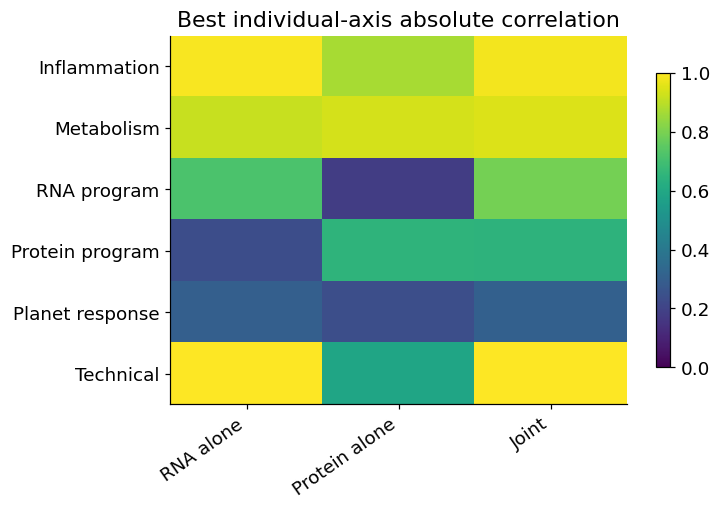

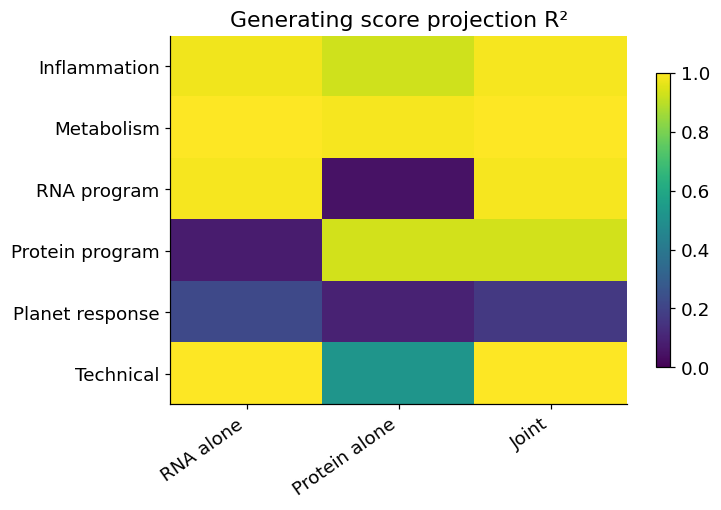

,RNA alone,Protein alone,Joint
Inflammation,0.988,0.868,0.982
Metabolism,0.914,0.936,0.946
RNA program,0.715,0.181,0.790
Protein program,0.236,0.650,0.647
Planet response,0.302,0.242,0.306
Technical,0.998,0.587,0.997


,RNA alone,Protein alone,Joint
Inflammation,0.980,0.929,0.986
Metabolism,0.997,0.987,0.997
RNA program,0.987,0.050,0.986
Protein program,0.076,0.930,0.930
Planet response,0.219,0.096,0.165
Technical,0.996,0.521,0.996


In [7]:
separate = {v: read_scores(f'independent_Asteron_{v}').loc[ids] for v in views}
teacher = load_truth()
representations = {**{f'{v} alone': z for v, z in separate.items()}, 'Joint': z_joint}
axis_recovery = pd.DataFrame({name: crosscorr(z, teacher['scores']['Asteron']).abs().max()
                              for name, z in representations.items()})
subspace_recovery = pd.DataFrame({name: truth_projection(z, teacher['scores']['Asteron'])
                                  for name, z in representations.items()})
heatmap(axis_recovery, 'Best individual-axis absolute correlation', vmin=0, vmax=1)
heatmap(subspace_recovery, 'Generating score projection R²', vmin=0, vmax=1)
display(axis_recovery.round(3), subspace_recovery.round(3))

## Read the outcome before deciding whether integration helped

Use the displayed values from **our current Asteron fits**. For inflammation, compare both its strongest individual-axis correlation and its activity-projection R² across the three representations. Do they tell the same story? Repeat this for the protein-only process. A clear axis and a score space that contains a process are different outcomes; neither is measured-abundance reconstruction R².

The next cell subtracts each separate fit's activity-projection R² from the joint value. A negative difference is a concrete case where this diagnostic did not improve. Small positive differences should also be read at their displayed scale rather than treated as universal benefits.

For the final reconstruction panels, `standardized(views[v])` centres each view and divides by one whole-table RMS scalar, matching the fitted model's view coordinates. `z_joint @ w.T` combines the **same shared scores** with the appropriate view's weights. `reconstruction_plot` displays the supplied prediction and residuals; it does not retrain or use truth.

**Before running:** RNA has exactly zero weights for the protein-only program. How much direct information can it contribute about that program, even in a joint model?

,RNA,Protein
True process,,
Inflammation,0.0054,0.0567
Metabolism,0.0005,0.0098
RNA program,-0.0014,0.9362
Protein program,0.8543,-0.0001
Planet response,-0.0543,0.0690
Technical,-0.0003,0.4750


Non-improvements relative to a separate view:


,RNA,Protein
RNA program,-0.001447,NaN
Protein program,NaN,-0.000117
Planet response,-0.054265,NaN
Technical,-0.000284,NaN


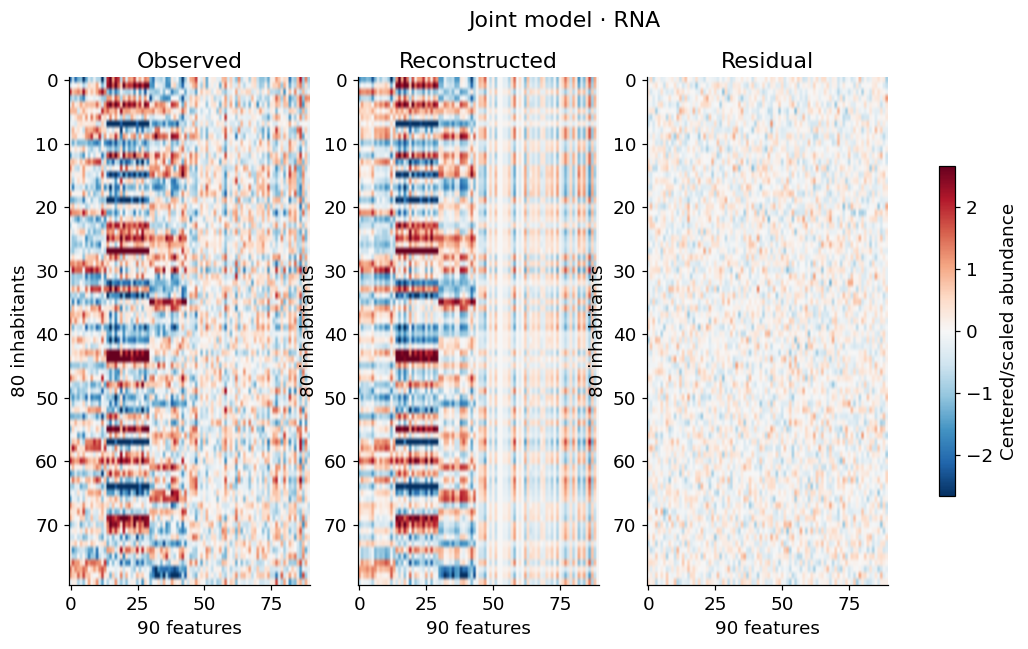

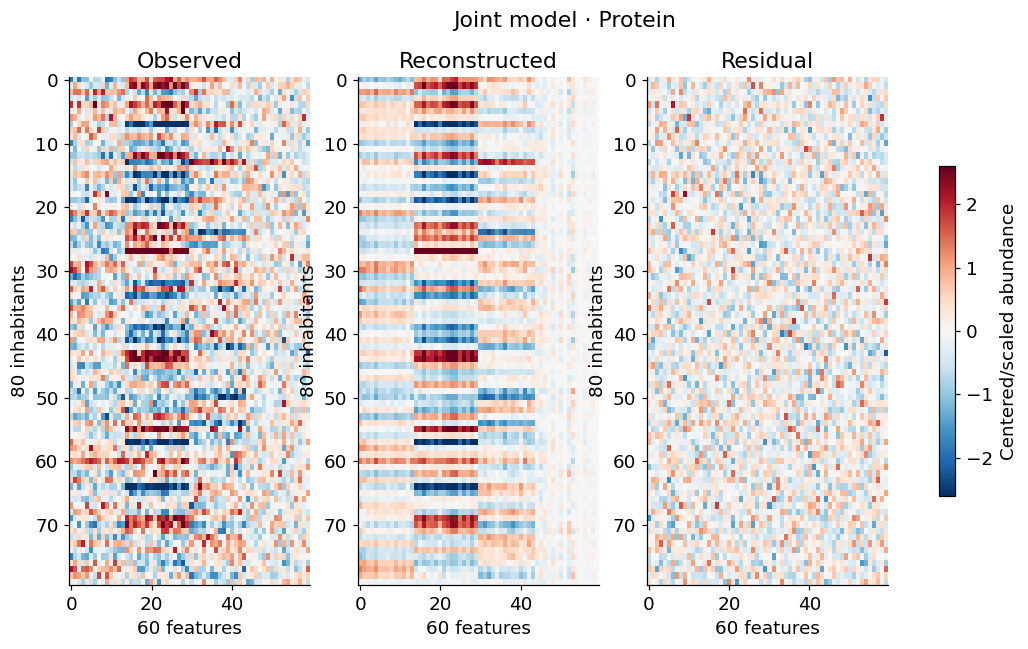

In [8]:
deltas = pd.DataFrame({v: subspace_recovery['Joint']-subspace_recovery[f'{v} alone'] for v in views})
display(deltas.rename_axis('True process').round(4))
print('Non-improvements relative to a separate view:')
display(deltas.where(deltas <= 0).dropna(how='all'))
for v in views:
    x = standardized(views[v])
    w = joint.get_weights()[v]
    reconstruction_plot(x, z_joint.to_numpy() @ w.to_numpy().T, f'Joint model · {v}', figsize=(12, 6))

## What changed when we fitted the views together?

The **joint Asteron RNA–protein model** gives each inhabitant one set of coordinates, with separate feature contributions in RNA and protein. This makes statistical sharing directly expressible within one model, while leaving noise, weak effects and technical variation to be interpreted.

Nonzero weights in both views do not establish a common causal mechanism. Better reconstruction does not guarantee a clearer biological axis, and integration need not improve every process. Which result in our comparisons best illustrates that limitation?

**Next we add Borealis**, whose inhabitants differ from Asteron's. Can a model share feature patterns across planets without pretending their samples are paired?

The following optional cell connects this fitted representation to mc-ASTRA's downstream format.

### Optional: carry the fitted model into mc-ASTRA

We keep the **existing Asteron two-view fit**. `mca.down.model_to_anndata(...)` aligns observations and metadata, extracts the model's scores, weights and R², and packages them into an AnnData object. Here `.X` becomes the 80 × 6 sample-factor representation, `.obs` contains sample metadata, `.var` holds per-factor variance summaries, and `.varm`/`.obsm` retain weights and view measurements for downstream analysis. This conversion does not fit a new model.

The helper also creates cell-count placeholders used by mc-ASTRA's broader workflows; they are missing values here because our experiment is sample-level. Read the final assertion as a check that the converted sample identifiers are unique and its factor coordinates finite.

In [9]:
import mc_astra as mca
amodel = mca.down.model_to_anndata(anndata_dict=views, metadata=mdata.obs, model=joint)
assert amodel.obs_names.is_unique and np.isfinite(amodel.X).all()
display(amodel)

AnnData object with n_obs × n_vars = 80 × 6
    obs: 'planet', 'disease', 'batch', 'RNA_n_cells', 'Protein_n_cells'
    var: 'Protein:group_1', 'RNA:group_1'
    uns: 'gene_loadings_columns', 'RNA_columns', 'Protein_columns'
    obsm: 'RNA', 'Protein'
    varm: 'gene_loadings'
    layers: None (.X)